# 16 · Baseline Representativeness & Data Limitations (`16_representativeness.py`)

Under IRB governance (CRR Article 179), models trained on historical development windows must stay representative of today's live portfolio—and every known data gap must be disclosed explicitly. In this walkthrough we verify `m2.representativeness_mart` (PSI comparing pre-2022 and pre-2025 training windows against December 2025 live balances) and `m2.data_limits_mart`.

<div style="background:#FFFFFF; border:1px solid #E5E7EB; border-radius:10px; padding:14px; margin:8px 0;">
<div style="font-family:Segoe UI,Arial,sans-serif; font-size:13px; font-weight:700; color:#051C2C; margin-bottom:8px;">IRB Representativeness &amp; Data-Gap Register</div>
<svg viewBox="0 0 920 110" width="100%" xmlns="http://www.w3.org/2000/svg">
<defs><marker id="arr" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#2251FF"/></marker></defs>
<rect x="20" y="18" width="170" height="68" rx="8" fill="#051C2C" stroke="#051C2C" stroke-width="1.5"/>
<text x="105.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Pre-2022 &amp; Pre-2025</text>
<text x="105.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">Development baselines</text>
<line x1="194" y1="52" x2="252" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="256" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="341.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Today (Dec 2025)</text>
<text x="341.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">Current live portfolio</text>
<line x1="430" y1="52" x2="488" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="492" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="577.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">PSI Drift Audit</text>
<text x="577.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">m2.representativeness_mart</text>
<line x1="666" y1="52" x2="724" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="728" y="18" width="170" height="68" rx="8" fill="#2251FF" stroke="#2251FF" stroke-width="1.5"/>
<text x="813.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Known Data Limits</text>
<text x="813.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">m2.data_limits_mart</text>
</svg></div>

We attach `module2_sample.duckdb` strictly read-only, check that `loan_share` sums cleanly to `1.0` inside every `(driver_name, baseline_window)` slice, and view the full `m2.data_limits_mart` disclosure register.

In [1]:
# Load path, DuckDB, pandas, I/O, and inline chart display utilities
# Import standard libraries to inspect saved marts read-only and render 300 dpi figures inline
import io
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Image, display

# Locate residential_mortgage/ root and attach module2_sample.duckdb strictly READ_ONLY
# Walk upward until reaching residential_mortgage/, then open an in-memory DuckDB connection
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Verify distribution shares sum to 1.0 per driver and baseline window in representativeness_mart
# Assert max share-sum deviation < 1e-4 and display the full Category A/B data_limits_mart table
max_share_err = con.execute("""
    SELECT max(abs(tot - 1.0)) FROM (
        SELECT driver_name, baseline_window, sum(loan_share) AS tot
        FROM m2.representativeness_mart
        GROUP BY 1, 2
    )
""").fetchone()[0]
assert max_share_err < 1e-4, f"Share normalization error {max_share_err}"
print(f"PASS  representativeness share sums match 1.0 (max error={max_share_err:.2e})")

con.execute("""
    SELECT category, limit_name, records_or_loans,
           round(share_pct, 2) AS share_pct,
           round(balance_share_pct, 2) AS balance_share_pct
    FROM m2.data_limits_mart
    ORDER BY category, limit_name
""").fetchdf()

PASS  representativeness share sums match 1.0 (max error=1.11e-16)


,category,limit_name,records_or_loans,share_pct,balance_share_pct
0,Category A: Data Deficiencies,cat_A_estimated_delinquent_accrued_interest,231,1.34,0.00
1,Category A: Data Deficiencies,cat_A_invalid_or_null_orig_ltv,0,0.00,0.00
2,Category A: Data Deficiencies,cat_A_late_populated_monthly_fields_count,4,0.00,0.00
3,Category A: Data Deficiencies,cat_A_masked_early_balances_in_snapshots,6098,7.26,7.87
4,Category A: Data Deficiencies,cat_A_missing_credit_score_in_snapshots,287,0.34,0.26
5,Category A: Data Deficiencies,cat_A_missing_dti_in_snapshots,1174,1.40,1.04
6,Category A: Data Deficiencies,cat_A_origination_field_restatement_events,11364154,0.00,0.00
7,Category A: Data Deficiencies,cat_A_pre2000_hpi_clamped_to_2000Q1,49,0.28,0.00
8,Category A: Data Deficiencies,cat_A_territory_hpi_national_fallback,51,0.30,0.00
9,Category A: Data Deficiencies,cat_A_unknown_arrears_XX_in_snapshots,0,0.00,0.00


Next we rank every underwriting driver by Population Stability Index (`psi_vs_today`) comparing pre-2022 and pre-2025 histories against December 2025, and chart the horizontal PSI drift comparison at 300 dpi (marking the standard `0.10` / `0.25` monitoring thresholds).

baseline_window,history_pre_2022,history_pre_2025
driver_name,,
occupancy,0.0021,0.0015
property_state_tier,0.0031,0.0022
orig_ltv,0.0520,0.0372
loan_purpose,0.0604,0.0465
credit_score,0.1074,0.0769
dti,0.2544,0.1931
ltv_indexed,0.3887,0.2897
note_rate,0.7502,0.4526


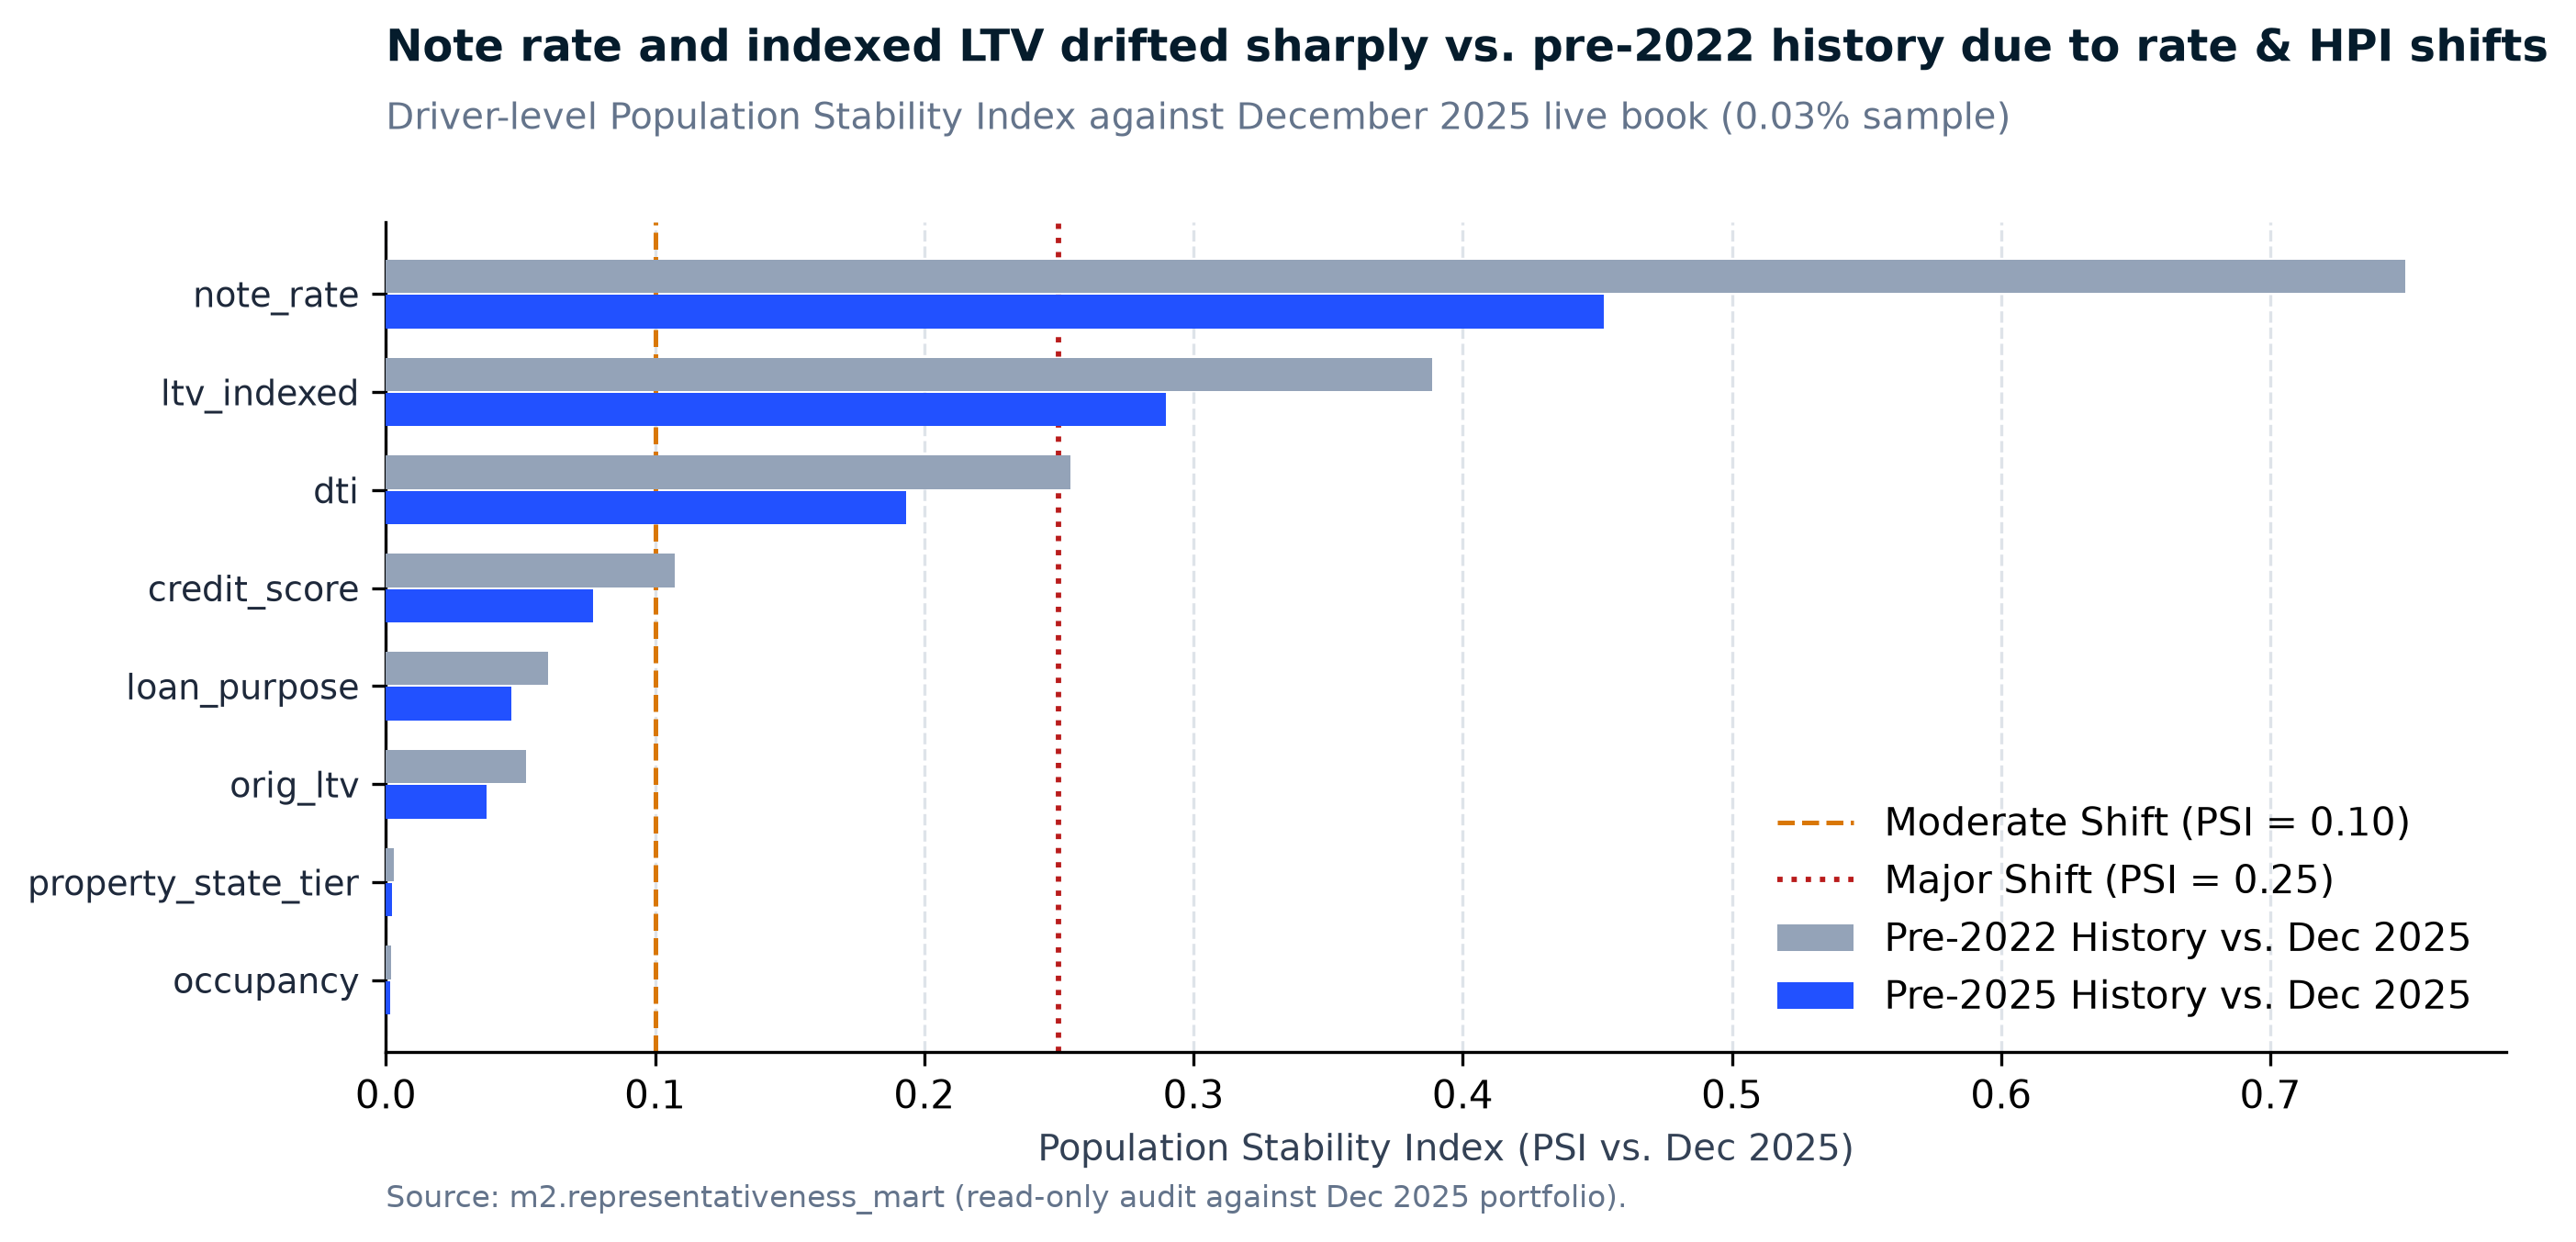

In [2]:
# Summarize and plot PSI vs December 2025 across all eight portfolio drivers
# Pivot psi_vs_today by driver_name and baseline_window and render clean grouped bars via BytesIO
psi_df = con.execute("""
    SELECT driver_name, baseline_window, max(psi_vs_today) AS psi_vs_today
    FROM m2.representativeness_mart
    WHERE baseline_window IN ('history_pre_2022', 'history_pre_2025')
    GROUP BY 1, 2
""").fetchdf().pivot(index="driver_name", columns="baseline_window", values="psi_vs_today").sort_values("history_pre_2025")
display(psi_df.round(4))

fig, ax = plt.subplots(figsize=(10.0, 4.5), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
y = range(len(psi_df))
ax.barh([i + 0.18 for i in y], psi_df["history_pre_2022"], height=0.34, color="#94A3B8", label="Pre-2022 History vs. Dec 2025", zorder=3)
ax.barh([i - 0.18 for i in y], psi_df["history_pre_2025"], height=0.34, color="#2251FF", label="Pre-2025 History vs. Dec 2025", zorder=3)
ax.axvline(0.10, color="#D97706", linestyle="--", linewidth=1.2, label="Moderate Shift (PSI = 0.10)")
ax.axvline(0.25, color="#B91C1C", linestyle=":", linewidth=1.4, label="Major Shift (PSI = 0.25)")
ax.set_yticks(list(y))
ax.set_yticklabels(psi_df.index, fontsize=9, color="#1E293B")
ax.grid(axis="x", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Population Stability Index (PSI vs. Dec 2025)", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="lower right")
fig.text(0.20, 0.94, "Note rate and indexed LTV drifted sharply vs. pre-2022 history due to rate & HPI shifts", fontsize=11.5, fontweight="bold", color="#051C2C")
fig.text(0.20, 0.885, "Driver-level Population Stability Index against December 2025 live book (0.03% sample)", fontsize=9.5, color="#64748B")
fig.text(0.20, 0.015, "Source: m2.representativeness_mart (read-only audit against Dec 2025 portfolio).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.20, right=0.97, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))


Next we inspect `m2.psi_by_year_mart` year-by-year from 2000 to 2025 (`P1-1`) so we can pinpoint exactly which calendar years drove `note_rate`, `ltv_indexed`, and `credit_score` shifts relative to December 2025.

PASS  2025 self-PSI check: 0.00e+00


driver_name,credit_score,ltv_indexed,note_rate
snapshot_year,,,
2018,0.0112,0.1665,0.8551
2019,0.0095,0.1366,0.9075
2020,0.0040,0.1185,0.4075
2021,0.0023,0.0765,0.3500
2022,0.0021,0.0323,0.2444
2023,0.0005,0.0080,0.0659
2024,0.0000,0.0020,0.0113
2025,0.0000,0.0000,0.0000


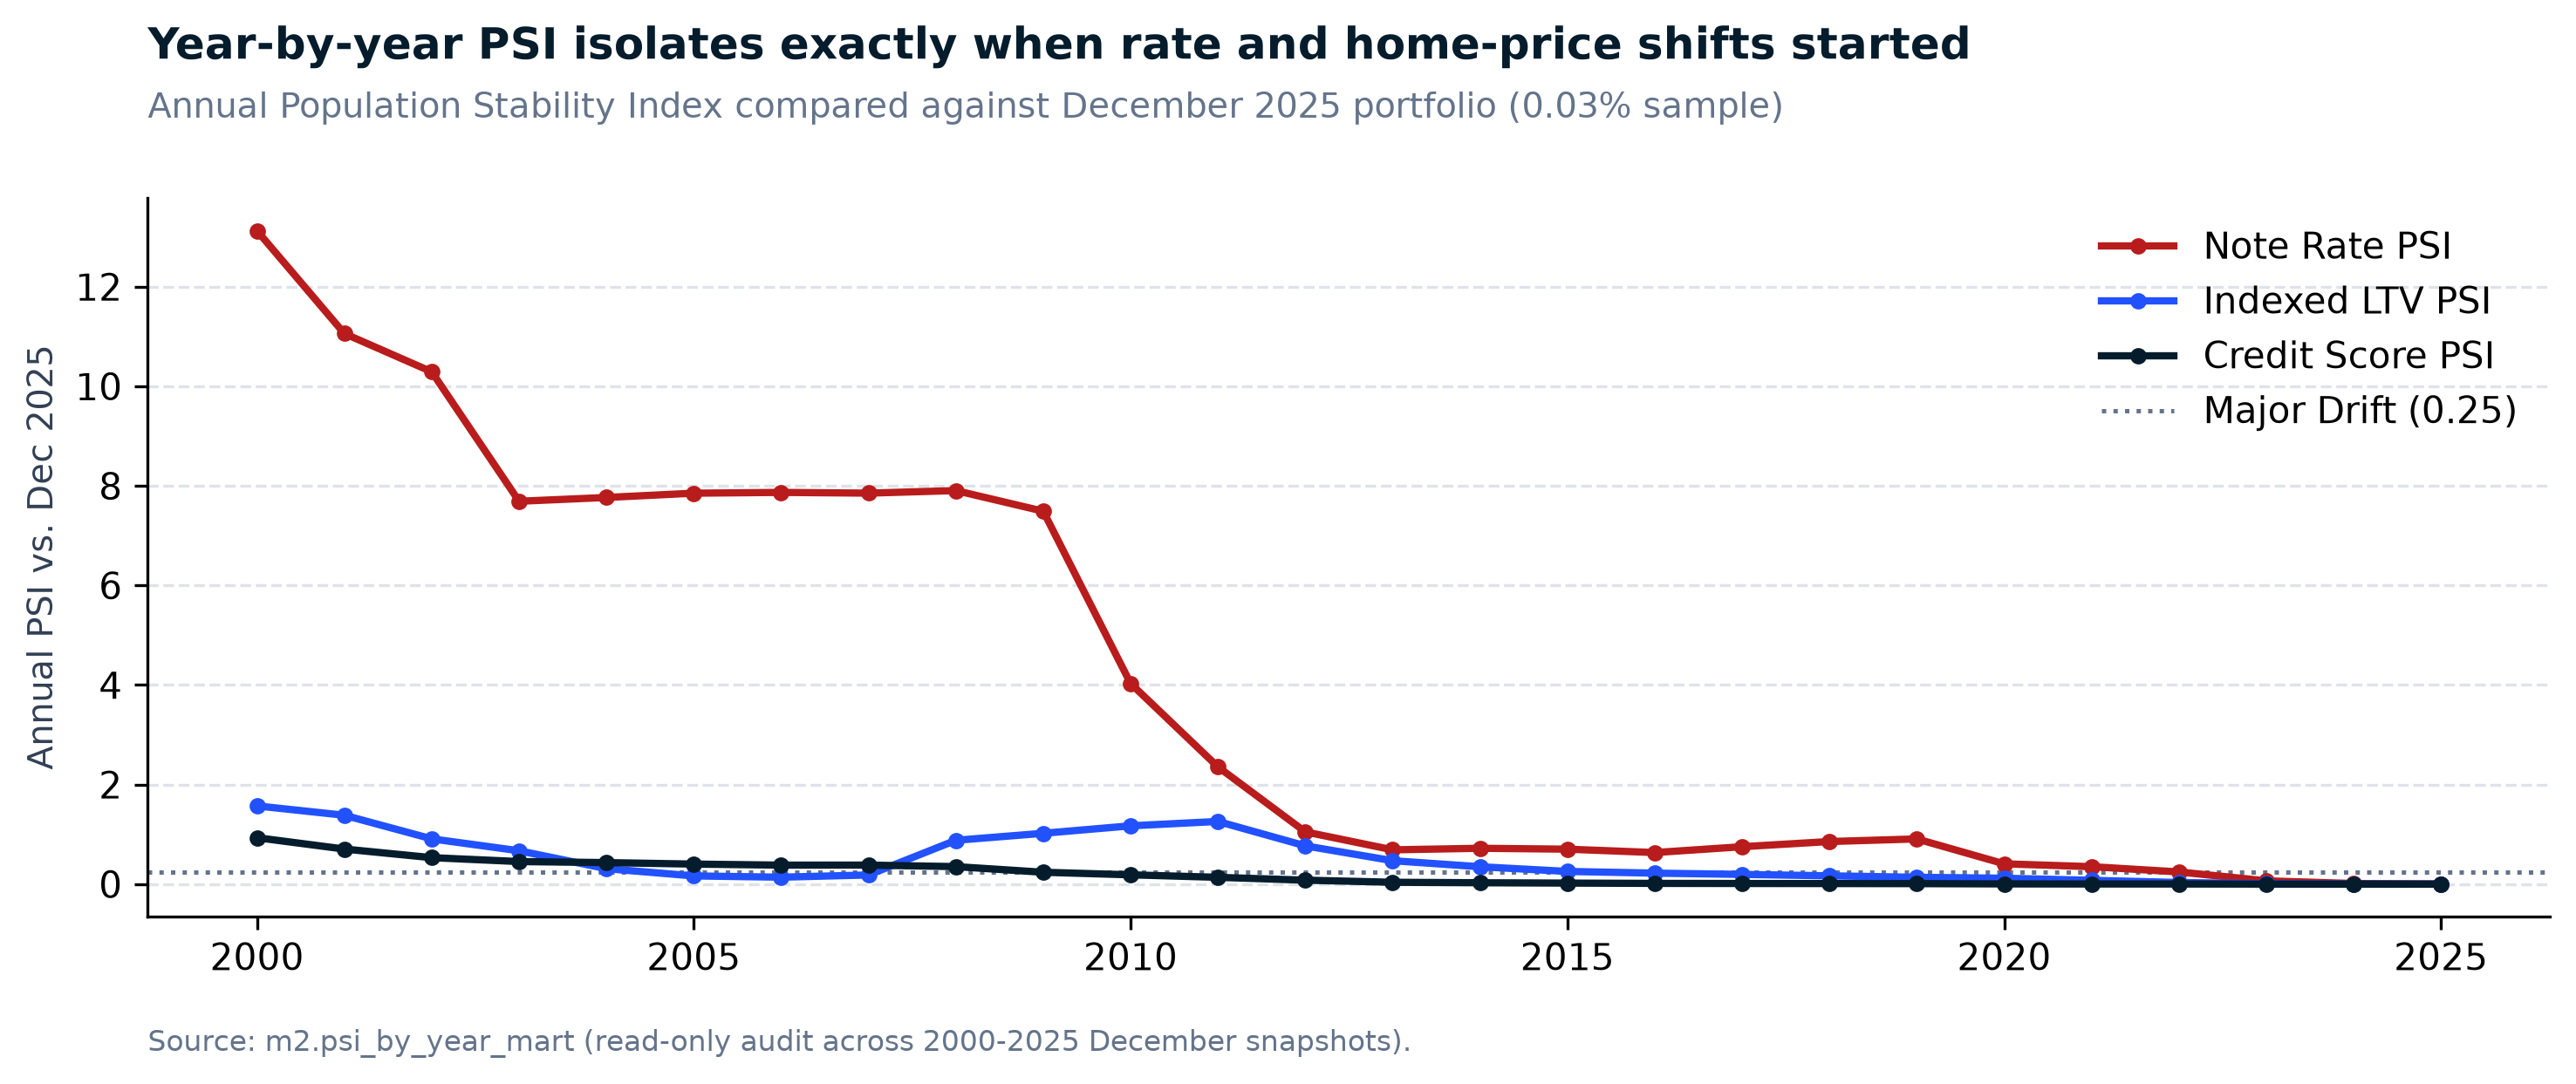

In [3]:
# Verify year-by-year PSI drift history and confirm latest snapshot year equals 0.0
# Query m2.psi_by_year_mart across key drivers and plot annual PSI curves via BytesIO
zero_err = con.execute("SELECT max(abs(psi_vs_today)) FROM m2.psi_by_year_mart WHERE snapshot_year = 2025").fetchone()[0]
assert zero_err < 1e-9, f"Non-zero 2025 self-PSI: {zero_err}"
print(f"PASS  2025 self-PSI check: {zero_err:.2e}")

psi_yr = con.execute("""
    SELECT snapshot_year, driver_name, psi_vs_today
    FROM m2.psi_by_year_mart
    WHERE driver_name IN ('note_rate', 'ltv_indexed', 'credit_score')
    ORDER BY snapshot_year
""").fetchdf().pivot(index="snapshot_year", columns="driver_name", values="psi_vs_today")
display(psi_yr.tail(8).round(4))

fig, ax = plt.subplots(figsize=(10.2, 4.1), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
for drv, col, lbl in [
    ("note_rate", "#B91C1C", "Note Rate PSI"),
    ("ltv_indexed", "#2251FF", "Indexed LTV PSI"),
    ("credit_score", "#051C2C", "Credit Score PSI"),
]:
    ax.plot(psi_yr.index, psi_yr[drv], marker="o", markersize=3.5, linewidth=2.0, color=col, label=lbl, zorder=3)
ax.axhline(0.25, color="#64748B", linestyle=":", linewidth=1.2, label="Major Drift (0.25)")
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Annual PSI vs. Dec 2025", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="upper right")
fig.text(0.07, 0.94, "Year-by-year PSI isolates exactly when rate and home-price shifts started", fontsize=12, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Annual Population Stability Index compared against December 2025 portfolio (0.03% sample)", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.psi_by_year_mart (read-only audit across 2000-2025 December snapshots).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()